## Исследование датасета

In [52]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from catboost import CatBoostRegressor

In [53]:
# Загружаем данные
path = "/kaggle/input/competitions/jpx-tokyo-stock-exchange-prediction/train_files/"
prices = pd.read_csv(path + "stock_prices.csv")

print(f"Размер датасета: {prices.shape}")
print(f"Количество признаков: {prices.shape[1]}")

display(prices.head())
display(prices.describe().T)
prices.info()

Размер датасета: (2332531, 12)
Количество признаков: 12


,RowId,Date,SecuritiesCode,Open,High,Low,Close,Volume,AdjustmentFactor,ExpectedDividend,SupervisionFlag,Target
0,20170104_1301,2017-01-04,1301,2734.0,2755.0,2730.0,2742.0,31400,1.0,NaN,False,0.000730
1,20170104_1332,2017-01-04,1332,568.0,576.0,563.0,571.0,2798500,1.0,NaN,False,0.012324
2,20170104_1333,2017-01-04,1333,3150.0,3210.0,3140.0,3210.0,270800,1.0,NaN,False,0.006154
3,20170104_1376,2017-01-04,1376,1510.0,1550.0,1510.0,1550.0,11300,1.0,NaN,False,0.011053
4,20170104_1377,2017-01-04,1377,3270.0,3350.0,3270.0,3330.0,150800,1.0,NaN,False,0.003026


,count,mean,std,min,25%,50%,75%,max
SecuritiesCode,2332531.0,5894.835185,2.404161e+03,1301.000000,3891.000000,6238.0,7965.000000,9.997000e+03
Open,2324923.0,2594.510783,3.577192e+03,14.000000,1022.000000,1812.0,3030.000000,1.099500e+05
High,2324923.0,2626.539682,3.619363e+03,15.000000,1035.000000,1834.0,3070.000000,1.105000e+05
Low,2324923.0,2561.227039,3.533494e+03,13.000000,1009.000000,1790.0,2995.000000,1.072000e+05
Close,2324923.0,2594.023446,3.576538e+03,14.000000,1022.000000,1811.0,3030.000000,1.095500e+05
Volume,2332531.0,691936.556556,3.911256e+06,0.000000,30300.000000,107100.0,402100.000000,6.436540e+08
AdjustmentFactor,2332531.0,1.000508,6.773040e-02,0.100000,1.000000,1.0,1.000000,2.000000e+01
ExpectedDividend,18865.0,22.017730,2.988245e+01,0.000000,5.000000,15.0,30.000000,1.070000e+03
Target,2332293.0,0.000445,2.339879e-02,-0.578541,-0.010499,0.0,0.010532,1.119512e+00


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2332531 entries, 0 to 2332530
Data columns (total 12 columns):
 #   Column            Dtype  
---  ------            -----  
 0   RowId             object 
 1   Date              object 
 2   SecuritiesCode    int64  
 3   Open              float64
 4   High              float64
 5   Low               float64
 6   Close             float64
 7   Volume            int64  
 8   AdjustmentFactor  float64
 9   ExpectedDividend  float64
 10  SupervisionFlag   bool   
 11  Target            float64
dtypes: bool(1), float64(7), int64(2), object(2)
memory usage: 198.0+ MB


Исследуем пропуски и дубликаты в датасете. 

,missing_count,missing_pct
ExpectedDividend,2313666,99.191222
Open,7608,0.326169
High,7608,0.326169
Low,7608,0.326169
Close,7608,0.326169
Target,238,0.010204


Дубликаты Date + SecuritiesCode: 0
Начало периода: 2017-01-04 00:00:00
Конец периода: 2021-12-03 00:00:00
Количество торговых дней: 1202
Количество акций: 2000


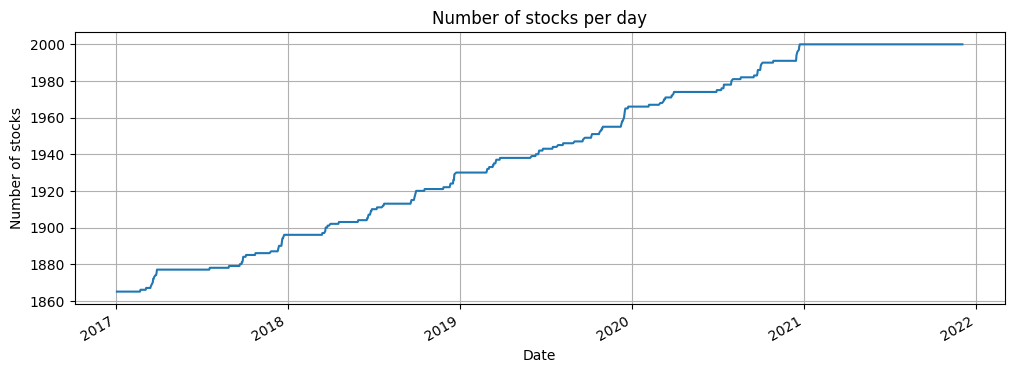

In [54]:
# Количество пропусков и их доля
missing = pd.DataFrame({
    "missing_count": prices.isna().sum(),
    "missing_pct": prices.isna().mean() * 100
})

display(
    missing[missing["missing_count"] > 0]
    .sort_values("missing_pct", ascending=False)
)

# Дубликаты по акции и дате
print(
    "Дубликаты Date + SecuritiesCode:",
    prices.duplicated(["Date", "SecuritiesCode"]).sum())
prices["Date"] = pd.to_datetime(prices["Date"])

print("Начало периода:", prices["Date"].min())
print("Конец периода:", prices["Date"].max())
print("Количество торговых дней:", prices["Date"].nunique())
print("Количество акций:", prices["SecuritiesCode"].nunique())

stocks_per_day = prices.groupby("Date")["SecuritiesCode"].nunique()

stocks_per_day.plot(figsize=(12, 4), title="Number of stocks per day")
plt.ylabel("Number of stocks")
plt.grid()
plt.show()

count    2.332293e+06
mean     4.450962e-04
std      2.339879e-02
min     -5.785414e-01
25%     -1.049869e-02
50%      0.000000e+00
75%      1.053159e-02
max      1.119512e+00
Name: Target, dtype: float64


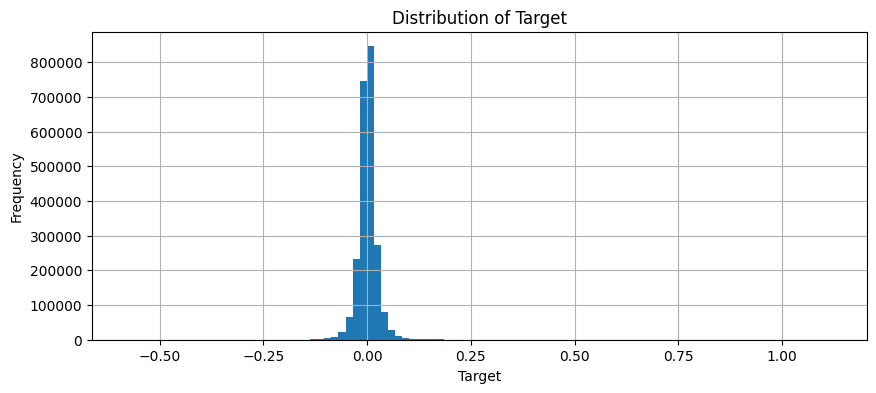

In [55]:
# Смотрим распределение таргетов
print(prices["Target"].describe())

prices["Target"].hist(bins=100, figsize=(10, 4))
plt.title("Distribution of Target")
plt.xlabel("Target")
plt.ylabel("Frequency")
plt.show()

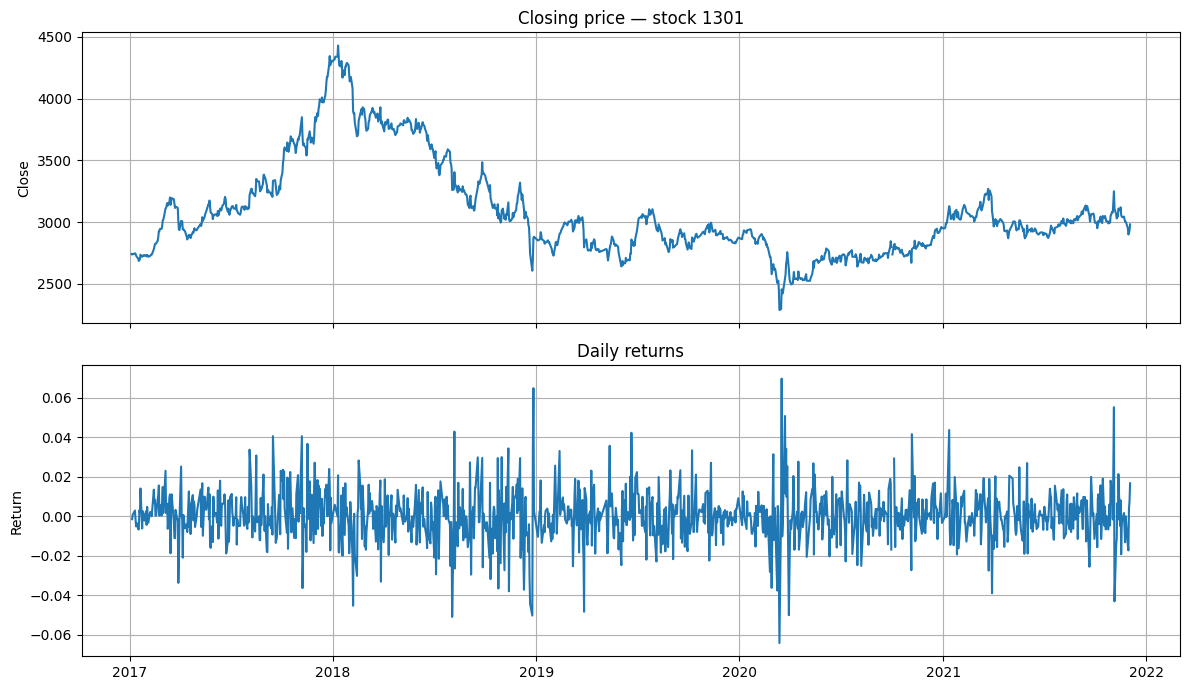

In [56]:
# Рисуем графики изменения цены выхода и доходности одной акции, а именно акции 1301 
code = prices["SecuritiesCode"].iloc[0]

stock = (
    prices[prices["SecuritiesCode"] == code]
    .sort_values("Date")
    .copy()
)

stock["Return"] = stock["Close"].pct_change(fill_method=None)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(stock["Date"], stock["Close"])
axes[0].set_title(f"Closing price — stock {code}")
axes[0].set_ylabel("Close")
axes[0].grid()

axes[1].plot(stock["Date"], stock["Return"])
axes[1].set_title("Daily returns")
axes[1].set_ylabel("Return")
axes[1].grid()

plt.tight_layout()
plt.show()

## Построение модели

Перед построением модели удаляем параметр ExpectedDividend (много пропусков) и дополнительно создаем искусственные параметры: Return_1d (доходность акции между соседними торговыми днями), Return_lag_1, Return_lag_2, Return_lag_5 (лаги Return_1d на 1,2,5 соответственно), Year, Month и DayOfWeek.

In [57]:
df = prices.copy()
df = df.drop(columns=["ExpectedDividend"])

df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values(["SecuritiesCode", "Date"]).reset_index(drop=True)

# Доходность акции между соседними торговыми днями
df["Return_1d"] = (
    df.groupby("SecuritiesCode")["Close"]
      .pct_change(fill_method=None)
)

g = df.groupby("SecuritiesCode", sort=False)

# Временной блок: признаки строятся отдельно для каждой акции
df["Return_lag_1"] = g["Return_1d"].shift(1)
df["Return_lag_2"] = g["Return_1d"].shift(2)
df["Return_lag_5"] = g["Return_1d"].shift(5)

# Прогноз временной модели: средняя доходность за предыдущие 20 дней.
df["TimeSeries_forecast"] = (
    g["Return_1d"]
      .transform(lambda s: s.rolling(20, min_periods=5).mean())
)

# Скользящая волатильность
df["Volatility_20d"] = (
    g["Return_1d"]
      .transform(lambda s: s.rolling(20, min_periods=5).std())
)

# Календарные признаки
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["DayOfWeek"] = df["Date"].dt.dayofweek

Признак SecuritiesCode рассматриваем как категориальный, чтобы модель не училась на нем как на числовом (есть логичный порядок). Разбиваем на тренировочную и валидационную выборки, при этом пропуски числовых данных заполняем медианами, рассчитанными только на тренировочной выборке. Далее реализуем CatBoost. 

In [58]:
feature_cols = [
    "SecuritiesCode", "Year", "Month",
    "DayOfWeek", "Open", "High",
    "Low", "Close", "Volume",
    "AdjustmentFactor", "Return_1d", "Return_lag_1",
    "Return_lag_2", "Return_lag_5", "TimeSeries_forecast", 
    "Volatility_20d",
]

cat_features = ["SecuritiesCode"]

g = df.groupby("SecuritiesCode", sort=False)

df["Target"] = g["Return_1d"].shift(-1)
df["TargetDate"] = g["Date"].shift(-1)

split_date = pd.Timestamp("2021-01-01")

model_df = df.dropna(subset=["Target"]).copy()

train_df = model_df[
    (model_df["Date"] < split_date) &
    (model_df["TargetDate"] < split_date)
].copy()

valid_df = model_df[
    (model_df["Date"] >= split_date) &
    (model_df["TargetDate"] >= split_date)
].copy()

# Заполняем пропуски числовых признаков медианами, рассчитанными только на обучающем периоде
numeric_features = [
    c for c in feature_cols if c not in cat_features
]

medians = train_df[numeric_features].median()

train_df.loc[:, numeric_features] = (
    train_df[numeric_features].fillna(medians)
)
valid_df.loc[:, numeric_features] = (
    valid_df[numeric_features].fillna(medians)
)

# CatBoost воспринимает код акции как категориальный признак
train_df["SecuritiesCode"] = train_df["SecuritiesCode"].astype(str)
valid_df["SecuritiesCode"] = valid_df["SecuritiesCode"].astype(str)

model = CatBoostRegressor(
    iterations=750,
    depth=7,
    learning_rate=0.02,
    loss_function="RMSE",
    eval_metric="RMSE",
    l2_leaf_reg=15,
    random_seed=42,
    verbose=100,
    allow_writing_files=False
)


model.fit(
    train_df[feature_cols],
    train_df["Target"],
    cat_features=cat_features,
    eval_set=(valid_df[feature_cols], valid_df["Target"]),
    early_stopping_rounds=50,
)

valid_df["prediction"] = model.predict(valid_df[feature_cols])

0:	learn: 0.0772701	test: 0.0291718	best: 0.0291718 (0)	total: 605ms	remaining: 7m 33s
100:	learn: 0.0291639	test: 0.0221869	best: 0.0221869 (100)	total: 40.5s	remaining: 4m 20s
200:	learn: 0.0258002	test: 0.0219706	best: 0.0219706 (200)	total: 1m 31s	remaining: 4m 9s
300:	learn: 0.0250758	test: 0.0219672	best: 0.0219669 (289)	total: 2m 23s	remaining: 3m 33s
Stopped by overfitting detector  (50 iterations wait)

bestTest = 0.02196578767
bestIteration = 327

Shrink model to first 328 iterations.


Реализация метрики из условия соревнования.

In [59]:
# Функция метрики
def calc_spread_return_sharpe(
    df,
    portfolio_size=200,
    toprank_weight_ratio=2,
):
    daily_returns = []

    weights = np.linspace(
        start=toprank_weight_ratio,
        stop=1,
        num=portfolio_size,
    )

    for date, day in df.groupby("Date"):
        day = day.dropna(subset=["prediction", "Target"])

        if len(day) < 2 * portfolio_size:
            continue

        # Сортировка по прогнозу: лучший прогноз первым
        ranked = day.sort_values(
            "prediction",
            ascending=False,
        )

        # Покупаем акции с наибольшими прогнозами
        purchase = (
            ranked["Target"].iloc[:portfolio_size].to_numpy()
            * weights
        ).sum() / weights.mean()

        # Продаём акции с наименьшими прогнозами
        short = (
            ranked["Target"].iloc[-portfolio_size:][::-1].to_numpy()
            * weights
        ).sum() / weights.mean()

        daily_returns.append(purchase - short)

    daily_returns = pd.Series(daily_returns, dtype=float)

    if len(daily_returns) < 2 or daily_returns.std() == 0:
        return np.nan, daily_returns

    sharpe = daily_returns.mean() / daily_returns.std()

    return sharpe, daily_returns

In [60]:
# Считаем метрику для нашей модели
sharpe, daily_returns = calc_spread_return_sharpe(
    valid_df[["Date", "prediction", "Target"]].copy(),
    portfolio_size=200,
    toprank_weight_ratio=2,
)

print(f"Validation Sharpe: {sharpe:.6f}")
print(f"Средняя дневная spread-доходность: {daily_returns.mean():.6f}")
print(f"Стандартное отклонение: {daily_returns.std():.6f}")
print(f"Количество дней: {len(daily_returns)}")

Validation Sharpe: 0.124574
Средняя дневная spread-доходность: 0.363098
Стандартное отклонение: 2.914722
Количество дней: 225


## Анализ результатов

В качестве анализа рассматриваем график доходности одной акции (1301) и график накапливания дневного спреда. 

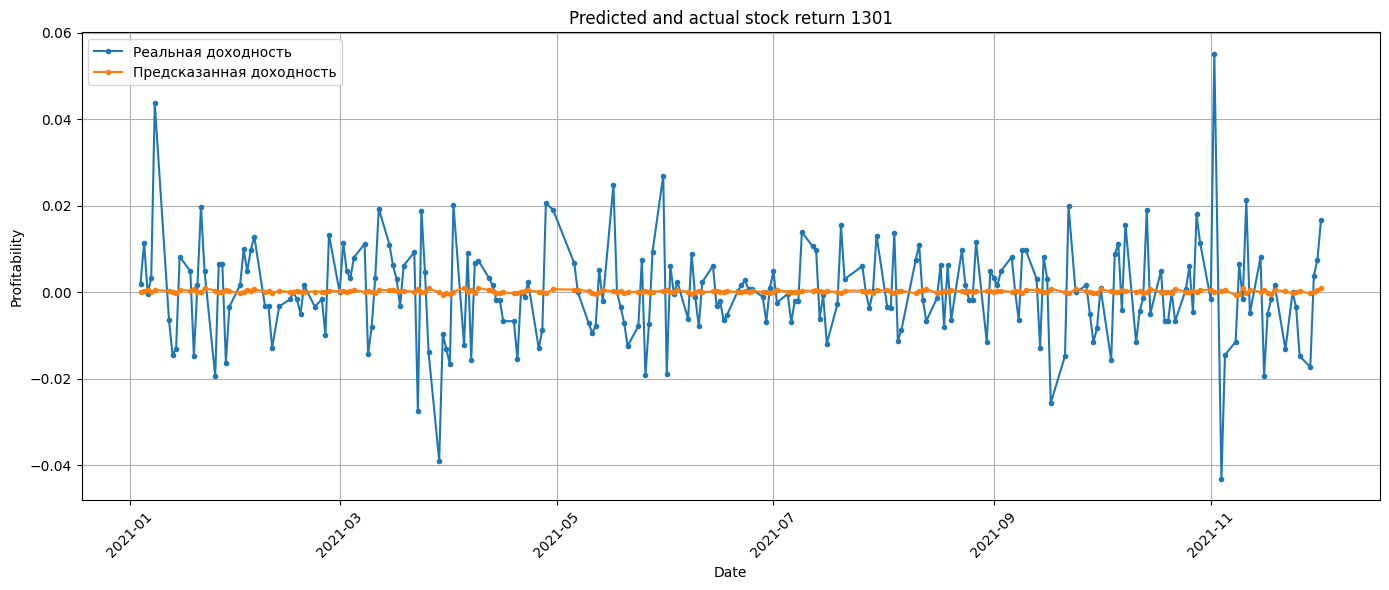

In [65]:
# Выбираем конкретную акцию
security_code = 1301

stock = valid_df[
    valid_df["SecuritiesCode"].astype(str) == str(security_code)
].copy()

# Сортируем по дате
stock = stock.sort_values("Date")

# Строим график
plt.figure(figsize=(14, 6))

plt.plot(
    stock["Date"],
    stock["Target"],
    label="Реальная доходность",
    marker="o",
    markersize=3,
)

plt.plot(
    stock["Date"],
    stock["prediction"],
    label="Предсказанная доходность",
    marker="o",
    markersize=3,
)

plt.title(f"Predicted and actual stock return {security_code}")
plt.xlabel("Date")
plt.ylabel("Profitability")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

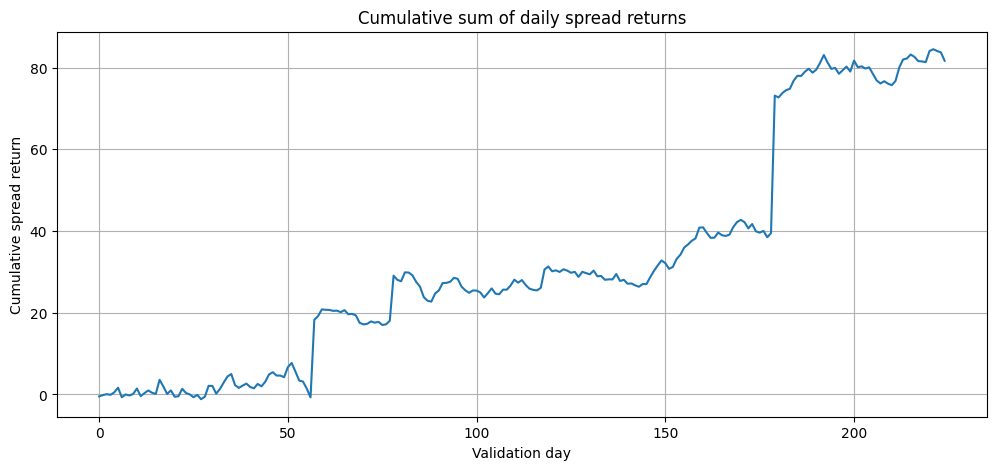

In [64]:
daily_returns.index = pd.RangeIndex(len(daily_returns))

daily_returns.cumsum().plot(figsize=(12, 5))
plt.title("Cumulative sum of daily spread returns")
plt.xlabel("Validation day")
plt.ylabel("Cumulative spread return")
plt.grid(True)
plt.show()